# 27 · A8 tests 2–4: retraining the aligned space (bigger vocabulary, neighbourhood context, both)

Fixed in `PLAN.md` (amendment A8) before this notebook ran. Notebook 11's recipe, budget and seeds; CLIP text
tower; strings encoded in notebook 11 read from `text_clip.npz` (float16), new strings encoded here.

- **B0:** notebook 11's recipe rerun (control). **K8:** its U1(a) within ±0.02 of notebook 11's 0.267.
- **V:** more OpenStreetMap tags (key=value, ≥ 1,000 training pixels, not already in the vocabulary, none named by
  an A6 rule) and language-model paraphrases of every caption wording list (5 kept per list; 8 wordings each).
- **C:** A7's 256 neighbourhood features instead of the pixel's 64 numbers (plus the POWER summary, as before).
- **V+C:** both.
- **Measures:** U1(a) (notebook 11), never-seen median AP/chance (notebook 21), Method 2-G median F1 on the 40
  held-out questions (notebook 26); Method 1-G and the published Method 1 as information.
- **Pass (against B0):** R1 U1(a) ≥ +0.03, lower bound > 0; or R2 never-seen median ≥ 1.5 × B0's, lower bound of the
  difference > 0; or R3 Method 2-G median F1 ≥ +0.03, lower bound > 0; and no harm (U1(a) ≥ B0 − 0.01, never-seen
  ≥ 0.9 × B0's, Method 2-G ≥ B0 − 0.01).

The next six cells are notebook 11's loading code (cells 1, 2, 4, 8, 10), unchanged.

In [1]:
import json
import time

import numpy as np
import pandas as pd

from askmap.catalogue import area_classes
from askmap.config import PROJECT_ROOT, data_root, load_config
from askmap.layers import SOLAR_LATER, official_leaf_map
from askmap.plan import AreaContext, execute
from askmap.power import add_derived, fetch_daily, pixel_cells
from askmap.tiles import area_tiles, pixel_lonlat
from askmap.universe import Universe, box_of

cfg = load_config(PROJECT_ROOT / "configs" / "feasibility.yaml")
Q = load_config(PROJECT_ROOT / "configs" / "queries.yaml")["queries"]
RW = load_config(PROJECT_ROOT / "configs" / "reworded.yaml")["reworded"]
ROOT = data_root()
RES = PROJECT_ROOT / "outputs" / "results"
FIG = PROJECT_ROOT / "outputs" / "figures"
CL, P, SC = cfg["classes"], cfg["power"], cfg["scoring"]
LEAVES, GROUPS = CL["leaves"], CL["groups"]
CATALOGUE = area_classes(cfg)
T_START = time.time()
cells = pd.read_parquet(ROOT / "power" / "universe_cells.parquet")
daily = {
    box: add_derived(fetch_daily(P, b, ROOT / "power" / f"universe_{box}_daily.nc"), P["low_wind_sun_pct"])
    for box, b in P["boxes"].items()
}
uni = Universe(cells=cells, daily=daily)
SEEN = ["north_dakota", "north_carolina"]
HELD = cfg["heldout_pools"]  # seen area -> held-out state
POOL_Q = {
    "north_dakota": "north_dakota",
    "north_carolina": "north_carolina",
    "minnesota": "north_dakota",
    "georgia": "north_carolina",
}  # pool -> area whose questions it answers
T = {}
for area in POOL_Q:
    for name, (tile, role) in area_tiles(cfg["areas"][area], cfg["grid"]).items():
        z = np.load(ROOT / "tiles" / f"{area}_{name}.npz")
        solar = z["solar"] if "solar" in z.files else None
        nwi = z["nwi"] if "nwi" in z.files else None
        valid = np.isfinite(z["ae"]).all(axis=0)
        if solar is not None:
            valid &= solar != SOLAR_LATER
        lon, lat = pixel_lonlat(tile)
        box = box_of(float(lon.mean()), float(lat.mean()), P["boxes"])
        iy, ix = pixel_cells(daily[box].lat.values, daily[box].lon.values, lat, lon)
        T[name] = {
            "area": area,
            "role": role,
            "valid": valid,
            "box": box,
            "iy": iy,
            "ix": ix,
            "cell": uni.index(box, iy, ix),
            "official": official_leaf_map(z["cdl"], LEAVES, CL, nwi=nwi, solar=solar),
        }
        if role == "test":
            T[name]["ae_map"] = np.load(ROOT / "maps" / f"ae_{name}.npz")["leaf"]
            T[name]["planted_map"] = np.load(ROOT / "maps" / f"planted_{name}.npz")["leaf"]
CTX, TILES = {}, {}
for area in POOL_Q:
    names = [n for n, t in T.items() if t["area"] == area]
    ds = daily[T[names[0]]["box"]]
    ac = np.zeros((ds.sizes["lat"], ds.sizes["lon"]), bool)
    for n in names:
        ac[T[n]["iy"], T[n]["ix"]] = True
    CTX[area] = AreaContext(
        leaves=LEAVES,
        groups=GROUPS,
        res_m=cfg["grid"]["res_m"],
        power=ds,
        area_cells=ac,
        pixel_cell={n: (T[n]["iy"], T[n]["ix"]) for n in names},
    )
    TILES[area] = {
        "train": [n for n in names if T[n]["role"] == "train"],
        "test": [n for n in names if T[n]["role"] == "test"],
    }


def answer(plan, pool, maps="official"):
    """Answer of a plan in a pool's test tiles, as one vector over their valid pixels (fixed tile order)."""
    tiles = TILES[pool]["test"]
    key = "official" if maps == "official" else f"{maps}_map"
    got = execute(plan, {n: T[n][key] for n in tiles}, CTX[pool])
    return np.concatenate([got[n][T[n]["valid"]] for n in tiles])


def question_text(q, wording, pool):
    text = q["question"] if wording != "reworded" else RW[q["id"]]
    if pool in ("minnesota", "georgia"):
        text = text.replace("North Dakota", "Minnesota").replace("North Carolina", "Georgia")
    return text


def n_extra(plan):
    return len(plan["near"]) + len(plan["climate"]) + int(plan["land"]["min_patch_ha"] is not None)


print(f"{len(T)} tiles loaded; pools {dict((a, TILES[a]['test']) for a in POOL_Q)}")

18 tiles loaded; pools {'north_dakota': ['Kidder', 'Foster', 'Eddy'], 'north_carolina': ['NC4', 'NC5', 'NC6'], 'minnesota': ['MN1', 'MN2', 'MN3'], 'georgia': ['GA1', 'GA2', 'GA3']}


In [2]:
import os

import matplotlib.pyplot as plt
import torch
from sklearn.metrics import average_precision_score

from askmap.aether_us import (
    Bank,
    TileScores,
    captions_for,
    climate_only_spec,
    concept_indices,
    group_mean,
    multiset_index,
    project,
    similarities,
    text_vectors,
    train,
)
from askmap.captions import Location, Vocab, fact_text, near_text
from askmap.layers import class_mask
from askmap.local_facts import distances, leaf_patch_ha, patch_area_ha, sample_pixels
from askmap.space import Items, specs_from

AU = load_config(PROJECT_ROOT / "configs" / "aether_us.yaml")
CAP = load_config(PROJECT_ROOT / "configs" / "captions.yaml")
SM, MCFG, CC, ACAP = cfg["sampling"], AU["model"], AU["concepts"], AU["captions"]
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
f = np.load(ROOT / "climate" / "facts.npz")
FACT_IDS, TABLE = [str(x) for x in f["ids"]], f["table"]
FAMILY = np.array(["long" if i.split("|")[0] == "sun" else i.split("|")[0] for i in FACT_IDS])
SUMMARY = np.load(ROOT / "climate" / "enc_summary.npy")
vocab = Vocab(CAP, LEAVES, GROUPS, FACT_IDS)
NEAR = vocab.near_classes
OTHER = LEAVES.index("other")
RES_M = cfg["grid"]["res_m"]
NPX = round(cfg["grid"]["tile_size_m"] / RES_M)
OV = AU["osm"]["vocab"]
USED = pd.read_csv(RES / "10_osm_used.csv").entry.tolist()
WORDS = [OV[k]["words"] for k in USED]
OUT = ROOT / "aether_us"
OUT.mkdir(exist_ok=True)
HF_CACHE = os.environ["HF_HOME"]
print(f"device {device}; {len(USED)} OpenStreetMap entries used; {len(FACT_IDS)} climate facts")


def osm_layers(area, name):
    z = np.load(ROOT / "osm" / f"{area}_{name}.npz")
    return np.stack([np.unpackbits(z[k])[: NPX * NPX].reshape(NPX, NPX) for k in USED]).astype(bool)


def local(leaf):
    return {
        "dist": distances(leaf, NEAR, LEAVES, GROUPS, RES_M),
        "patch_leaf": leaf_patch_ha(leaf, len(LEAVES), RES_M),
        "patch_crop": patch_area_ha(class_mask(leaf, "cropland", LEAVES, GROUPS), RES_M),
    }

device mps; 23 OpenStreetMap entries used; 4006 climate facts


In [3]:
parts = []
for k, (area, acfg) in enumerate(cfg["areas"].items()):
    for j, (name, (tile, role)) in enumerate(area_tiles(acfg, cfg["grid"]).items()):
        if role != "train":
            continue
        z = np.load(ROOT / "tiles" / f"{area}_{name}.npz")
        solar = z["solar"] if "solar" in z.files else None
        nwi = z["nwi"] if "nwi" in z.files else None
        leaf = official_leaf_map(z["cdl"], LEAVES, CL, nwi=nwi, solar=solar)
        valid = np.isfinite(z["ae"]).all(axis=0) & (leaf != OTHER)
        if solar is not None:
            valid &= solar != SOLAR_LATER
        lon, lat = pixel_lonlat(tile)
        box = box_of(float(lon.mean()), float(lat.mean()), P["boxes"])
        iy, ix = pixel_cells(daily[box].lat.values, daily[box].lon.values, lat, lon)
        cell = uni.index(box, iy, ix)
        lf = local(leaf)
        flat = sample_pixels(leaf, valid, SM["train_pixels_per_tile"], len(LEAVES), SM["seed"] + 100 * k + j)
        parts.append(
            {
                "ae": z["ae"].reshape(64, -1)[:, flat].T.astype(np.float32),
                "leaf": leaf.ravel()[flat],
                "dist": lf["dist"].reshape(-1, len(NEAR))[flat],
                "patch_leaf": lf["patch_leaf"].ravel()[flat],
                "patch_crop": lf["patch_crop"].ravel()[flat],
                "cell": cell.ravel()[flat],
                "osm": osm_layers(area, name).reshape(len(USED), -1)[:, flat].T,
                "area": np.full(len(flat), area),
            }
        )
LOC = {key: np.concatenate([p[key] for p in parts]) for key in parts[0]}
assert not cells.heldout.to_numpy()[LOC["cell"]].any()
N = len(LOC["leaf"])
XRAW = np.c_[LOC["ae"], SUMMARY[LOC["cell"]]]
MU, SD = XRAW.mean(0), XRAW.std(0)
SD[SD == 0] = 1.0


def standardise(ae, cell):
    return ((np.c_[ae, SUMMARY[cell]] - MU) / SD).astype(np.float32)


X = standardise(LOC["ae"], LOC["cell"])
print(
    f"{N:,} training locations; {X.shape[1]} inputs; share with any OpenStreetMap tag "
    f"{LOC['osm'].any(axis=1).mean():.2f}"
)

85,000 training locations; 971 inputs; share with any OpenStreetMap tag 0.17


In [4]:
def fact_year(fid):
    p = fid.split("|")
    return {
        "hist": p[3] if len(p) > 3 else None,
        "heat": p[3] if len(p) > 3 else None,
        "rain": p[2] if len(p) > 2 else None,
        "gdd": p[1] if len(p) > 1 else None,
    }.get(p[0])


CONCEPTS = [
    {"group": "land", "name": n, "text": CAP["land"][n][0], "kind": "land", "arg": n}
    for n in [x for x in LEAVES if x != "other"] + list(GROUPS)
]
CONCEPTS += [
    {"group": "osm", "name": k, "text": OV[k]["words"][0], "kind": "osm", "arg": i}
    for i, k in enumerate(USED)
]
CONCEPTS += [
    {
        "group": "distance",
        "name": f"near_{c}_{d}",
        "text": near_text([c], d, False, CAP, 0),
        "kind": "near",
        "arg": (NEAR.index(c), d),
    }
    for c in CC["near_classes"]
    for d in CC["near_distances_m"]
]
CONCEPTS += [
    {"group": "climate", "name": fid, "text": fact_text(fid, CAP, 0), "kind": "fact", "arg": i}
    for i, fid in enumerate(FACT_IDS)
    if fid.split("|")[0] in ("long", "sun") or fact_year(fid) == str(CC["climate_year"])
]
CGROUP = np.array([c["group"] for c in CONCEPTS])


def concept_truth(leaf, dist, osm, cell):
    out = np.zeros((len(CONCEPTS), len(leaf)), dtype=bool)
    for i, cn in enumerate(CONCEPTS):
        if cn["kind"] == "land":
            out[i] = np.isin(leaf, vocab.leaf_set(cn["arg"]))
        elif cn["kind"] == "osm":
            out[i] = osm[:, cn["arg"]]
        elif cn["kind"] == "near":
            out[i] = dist[:, cn["arg"][0]] <= cn["arg"][1]
        else:
            out[i] = TABLE[cell, cn["arg"]]
    return out


pd.Series(CGROUP).value_counts()

climate     190
osm          23
land         18
distance     12
Name: count, dtype: int64

In [5]:
POOLS = {}
for pool in POOL_Q:
    keep = {k: [] for k in ("ae", "leaf", "dist", "osm", "cell", "tile")}
    for ti, n in enumerate(TILES[pool]["test"]):
        flat = np.flatnonzero(T[n]["valid"].ravel())
        z = np.load(ROOT / "tiles" / f"{T[n]['area']}_{n}.npz")["ae"]
        keep["ae"].append(z.reshape(64, -1)[:, flat].T.astype(np.float16))
        keep["leaf"].append(T[n]["official"].ravel()[flat])
        keep["dist"].append(local(T[n]["official"])["dist"].reshape(-1, len(NEAR))[flat])
        keep["osm"].append(osm_layers(T[n]["area"], n).reshape(len(USED), -1)[:, flat].T)
        keep["cell"].append(T[n]["cell"].ravel()[flat])
        keep["tile"].append(np.full(len(flat), ti))
    POOLS[pool] = {k: np.concatenate(v) for k, v in keep.items()}
TRUTH = dict(np.load(ROOT / "maps" / "truth.npz"))
QROWS = []
for q in Q:
    seen = q["plan"]["area"]
    for wording, pool in (("as_written", seen), ("reworded", seen), ("as_written", HELD[seen])):
        n = len(POOLS[pool]["cell"])
        g = np.unpackbits(TRUTH[f"{q['id']}|{pool}"])[:n].astype(bool)
        QROWS.append(
            {
                "id": q["id"],
                "wording": wording,
                "pool": pool,
                "text": question_text(q, wording, pool),
                "truth": g,
                "persona": q["persona"],
                "has_climate": bool(q["plan"]["climate"]),
            }
        )
print({p: len(v["cell"]) for p, v in POOLS.items()}, f"{len(QROWS)} question-pool rows")

{'north_dakota': 1334667, 'north_carolina': 1334667, 'minnesota': 1334647, 'georgia': 1334667} 174 question-pool rows


## Notebook 12's held-out questions and plans (its cell 2, unchanged), and settings for this notebook

In [6]:
from askmap.plan import validate

HELDOUT = ["minnesota", "georgia"]

HP = {}
for pool in HELDOUT:
    ae, cl = [], []
    for n in TILES[pool]["test"]:
        flat = np.flatnonzero(T[n]["valid"].ravel())
        z = np.load(ROOT / "tiles" / f"{T[n]['area']}_{n}.npz")["ae"]
        ae.append(z.reshape(64, -1)[:, flat].T.astype(np.float32))
        cl.append(T[n]["cell"].ravel()[flat])
    HP[pool] = {"ae": np.concatenate(ae), "cell": np.concatenate(cl)}
TRUTH = dict(np.load(ROOT / "maps" / "truth.npz"))
LLM_DIR = PROJECT_ROOT / "outputs" / "llm" / "main"
rows = []
for q in Q:
    pool = HELD[q["plan"]["area"]]
    n = len(HP[pool]["cell"])
    g = np.unpackbits(TRUTH[f"{q['id']}|{pool}"])[:n].astype(bool)
    if g.sum() < SC["min_truth"]:
        continue
    rec = json.loads((LLM_DIR / f"as_written_{pool}_{q['id']}.json").read_text())
    plan, err = rec["plan"], rec["error"]
    if plan is not None:
        try:
            validate(plan, CATALOGUE, (2001, 2025))
            if plan["area"] != pool:
                plan, err = None, "wrong area"
        except (ValueError, KeyError, TypeError) as e:
            plan, err = None, f"invalid plan: {e}"
    rows.append(
        {
            "id": q["id"],
            "pool": pool,
            "text": question_text(q, "as_written", pool),
            "truth": g,
            "has_climate": bool(q["plan"]["climate"]),
            "plan": plan,
            "plan_error": err,
        }
    )
QS = rows
print(
    f"{len(QS)} scored held-out questions; {sum(r['plan'] is None for r in QS)} without a usable plan; "
    f"{sum(r['has_climate'] for r in QS)} with a climate condition"
)

40 scored held-out questions; 1 without a usable plan; 23 with a climate condition


In [7]:
import os

import torch

from askmap.aether_us import TextEncoder, climate_ok_tile
from askmap.captions import Vocab
from askmap.demo.serve import load_tiles
from askmap.landctx import context_features
from askmap.llm import make_client
from askmap.osm import new_tag_entries, tag_layers, tag_pixel_counts
from askmap.paraphrase import ask, extended_cap, keep_valid, parallel_lists
from askmap.score import paired_median_gap
from askmap.unseen import ap_and_chance, rule_mask, terms_in_captions
from askmap.zeroshot import distance_ok, leaf_grid, leaf_phrases, plan_text, zero_shot_leaf

UC = load_config(PROJECT_ROOT / "configs" / "unseen_words.yaml")
A7 = np.load(OUT / "land_methods_a7.npz")
SIZES, STD = tuple(int(s) for s in A7["mean_sizes"]), int(A7["std_size"])
BANNED = sorted({t for v in UC["unseen"].values() for t in v["check"]})
NEW_K, NEW_TAG_K, CANDIDATES, TAG_CANDIDATES = 5, 8, 8, 12
LLM = cfg["llm"]
LOG = PROJECT_ROOT / "outputs" / "llm" / "a8"
TXT = np.load(OUT / "text_clip.npz")
NB = 2000


def topk_f1(truth, score):
    k = int(truth.sum())
    return float(truth[np.argpartition(-score, k)[:k]].mean())


def unit(v):
    return v / np.linalg.norm(v, axis=-1, keepdims=True)


def plain(o):
    return o.item() if hasattr(o, "item") else str(o)


# notebook 11's validation split and location facts on the device (its cell 12, without the caption parts)
vr = np.random.default_rng(MCFG["seed"])
perm = vr.permutation(N)
n_val = int(MCFG["val_share"] * N)
VAL, TRN = np.sort(perm[:n_val]), np.sort(perm[n_val:])
t_ = torch.as_tensor
ITEMS = Items(
    t_(LOC["leaf"], dtype=torch.long, device=device),
    t_(LOC["dist"], dtype=torch.float32, device=device),
    t_(LOC["patch_leaf"], dtype=torch.float32, device=device),
    t_(LOC["patch_crop"], dtype=torch.float32, device=device),
    t_(LOC["cell"], dtype=torch.long, device=device),
)
print(
    f"A7 windows {SIZES} / std {STD}; {len(BANNED)} banned terms; {len(QS)} held-out questions; "
    f"{len(TRN):,} training / {len(VAL):,} validation locations"
)

A7 windows (5, 15) / std 15; 41 banned terms; 40 held-out questions; 76,500 training / 8,500 validation locations


## Training pixels again (the same sample as notebook 11): neighbourhood features and new OpenStreetMap tags

In [8]:
COUNTS = {}
geo = []  # per training tile: (area, name, tile, flat sample indices)
for k, (area, acfg) in enumerate(cfg["areas"].items()):
    for j, (name, (tile, role)) in enumerate(area_tiles(acfg, cfg["grid"]).items()):
        if role != "train":
            continue
        z = np.load(ROOT / "tiles" / f"{area}_{name}.npz")
        solar = z["solar"] if "solar" in z.files else None
        nwi = z["nwi"] if "nwi" in z.files else None
        leaf = official_leaf_map(z["cdl"], LEAVES, CL, nwi=nwi, solar=solar)
        valid = np.isfinite(z["ae"]).all(axis=0) & (leaf != OTHER)
        if solar is not None:
            valid &= solar != SOLAR_LATER
        flat = sample_pixels(leaf, valid, SM["train_pixels_per_tile"], len(LEAVES), SM["seed"] + 100 * k + j)
        geo.append((area, name, tile, flat))
        els = json.loads((ROOT / "osm" / f"{area}_{name}.json").read_text())["elements"]
        for t, c in tag_pixel_counts(els, tile, AU["osm"]["keys"]).items():
            COUNTS[t] = COUNTS.get(t, 0) + c
RULES = [m for v in UC["unseen"].values() for m in v["match"]]
NEW_TAGS = new_tag_entries(COUNTS, OV, RULES, AU["osm"]["min_train_px"])
print("new OpenStreetMap tags:", {t: COUNTS[t] for t in NEW_TAGS})
NEW_VOCAB = {t: {"match": [{t.split("=", 1)[0]: [t.split("=", 1)[1]]}]} for t in NEW_TAGS}
cf, ae_check, new_osm = [], [], []
for area, name, tile, flat in geo:
    ae = np.load(ROOT / "tiles" / f"{area}_{name}.npz")["ae"].astype(np.float32)
    ae_check.append(ae.reshape(64, -1)[:, flat].T)
    cf.append(context_features(ae, SIZES, STD).reshape(64 * (2 + len(SIZES)), -1)[:, flat].T)
    els = json.loads((ROOT / "osm" / f"{area}_{name}.json").read_text())["elements"]
    lay = tag_layers(els, tile, NEW_VOCAB)
    new_osm.append(np.stack([lay[t].ravel()[flat] for t in NEW_TAGS], axis=1).astype(bool))
if not np.array_equal(np.concatenate(ae_check), LOC["ae"]):
    raise AssertionError("the training sample differs from notebook 11's")
CF_TRAIN = np.concatenate(cf)
OSM_V = np.c_[LOC["osm"], np.concatenate(new_osm)]
del cf, ae_check, new_osm
print(
    f"context features {CF_TRAIN.shape}, finite {np.isfinite(CF_TRAIN).all()}; locations with a new tag",
    {t: int(OSM_V[:, len(USED) + i].sum()) for i, t in enumerate(NEW_TAGS)},
)

new OpenStreetMap tags: {'power=plant': 28338, 'leisure=resort': 2131, 'man_made=clearcut': 1882}


context features (85000, 256), finite True; locations with a new tag {'power=plant': 1713, 'leisure=resort': 34, 'man_made=clearcut': 18}


## Paraphrases from the open language model (asked once; replies saved in `outputs/llm/a8/`)

In [9]:
client = (
    make_client(LLM["base_url"])
    if not all(
        (LOG / f"{s}.json").exists()
        for s in ("phrases", "templates", "climate_words", "osm_words", "osm_new")
    )
    else None
)
PAR = parallel_lists(CAP)
SECTIONS = {
    "phrases": (
        {k: v for k, v in PAR.items() if k.startswith(("land.", "near.classes."))}
        | {"prefixes": [p for p in CAP["prefixes"] if p]},
        CANDIDATES,
        "Keys 'land.*' are names of a land cover (noun phrases such as 'corn fields'); keys 'near.classes.*' "
        "name what a place is near ('a wetland'); 'prefixes' are words that start a request before a land "
        "phrase ('Show ', 'Find '), each ending with a space.",
    ),
    "templates": (
        {k: v for k, v in PAR.items() if "templates" in k},
        CANDIDATES,
        "Each template is a clause that follows a land phrase, for example 'corn fields' + ' ' + template. "
        "{d} is a distance such as '300 m', {c} what it is measured to, {h} hectares, {season} a period of "
        "the year, {year} a year, {var} a climate variable, {adj} a word such as 'wettest', "
        "{p} a percentage, "
        "{n} a number of days, {t} a temperature in C, {mm} millimetres, {g} growing degree days, {tier} "
        "'third' or 'half', {x} a sunlight amount.",
    ),
    "climate_words": (
        {k: v for k, v in PAR.items() if k.endswith(".words")},
        CANDIDATES,
        "Keys '*.variables.*.words' name a climate variable as it is used inside a sentence; keys "
        "'*.seasons.*.words' name a period of the year (keep exactly the same months).",
    ),
    "osm_words": (
        {f"osm.{k}": OV[k]["words"] for k in USED},
        CANDIDATES,
        "Each key is an OpenStreetMap land use; the wordings are short noun phrases naming it.",
    ),
    "osm_new": (
        {f"osm_new.{t}": [] for t in NEW_TAGS},
        TAG_CANDIDATES,
        "Each key names an OpenStreetMap tag (key=value after 'osm_new.'); there are no wordings yet: write "
        "short plain-English noun phrases that name that kind of place.",
    ),
}
KEPT = {}
for sec, (lists, n, note) in SECTIONS.items():
    got = ask(client, LLM["models"]["main"], lists, n, BANNED, note, LOG / f"{sec}.json", LLM, 16000)
    for key, orig in lists.items():
        need = NEW_TAG_K if sec == "osm_new" else NEW_K
        KEPT[key] = keep_valid(orig, got[key], BANNED, need, prefix=key == "prefixes")
EXT = extended_cap(CAP, {k: v for k, v in KEPT.items() if k in PAR or k == "prefixes"})
WORDINGS = len(next(iter(parallel_lists(EXT).values())))
WORDS_V = [OV[k]["words"] + KEPT[f"osm.{k}"] for k in USED] + [KEPT[f"osm_new.{t}"] for t in NEW_TAGS]
(RES / "27_paraphrases.json").write_text(json.dumps(KEPT, indent=1))
print(f"{len(KEPT)} lists extended; parallel wordings per list now {WORDINGS}")
for key in (
    "land.corn",
    "land.wetland",
    "near.near_templates",
    "climate_year.templates",
    "prefixes",
    "osm.osm_golf",
    *[f"osm_new.{t}" for t in NEW_TAGS],
):
    print(f"{key}: {KEPT[key]}")

83 lists extended; parallel wordings per list now 8
land.corn: ['sweet corn acreage', 'field corn plots', 'yellow corn land', 'maize acreage', 'corn belt fields']
land.wetland: ['boggy areas', 'flooded lowlands', 'wet meadowland', 'marshland', 'swampy terrain']
near.near_templates: ['inside {d} of {c}', 'within a {d} radius of {c}', 'no farther than {d} from {c}', 'up to {d} away from {c}', 'within {d} distance of {c}']
climate_year.templates: ['where {season} {year} {var} ranked in the {adj} {p}% of years since 2001', 'when {season} {year} {var} fell within the {adj} {p}% of the record since 2001', 'where {season} {year} {var} was among the {adj} {p}% of years dating back to 2001', 'in {season} {year} when {var} hit the {adj} {p}% of historic years since 2001', 'where {season} {year} {var} placed in the {adj} {p}% of all years from 2001 onward']
prefixes: ['Locate ', 'Display ', 'Identify ', 'Search for ', 'Map ']
osm.osm_golf: ['golf fairway', 'golf greens', 'golf layout', 'golf prop

## Captions: notebook 11's generator (its cell 6), with the number of wordings and the tag words as inputs

In [10]:
def make_caps(cap, wordings, osm, words):
    voc = Vocab(cap, LEAVES, GROUPS, FACT_IDS, wordings)
    rng = np.random.default_rng(ACAP["seed"])
    cache = {}

    def true_facts(c):
        if c not in cache:
            on = np.flatnonzero(TABLE[c])
            cache[c] = {fam: on[FAMILY[on] == fam] for fam in ("hist", "heat", "rain", "gdd", "long")}
        return cache[c]

    locs = [
        Location(
            int(LOC["leaf"][j]),
            LOC["dist"][j],
            float(LOC["patch_leaf"][j]),
            float(LOC["patch_crop"][j]),
            true_facts(int(LOC["cell"][j])),
            str(LOC["area"][j]),
        )
        for j in range(N)
    ]
    rows = captions_for(locs, osm, voc, words, AU["osm"]["join"], ACAP, rng)
    comp = cap["composition"]
    fams = ["hist", "heat", "rain", "gdd", "long"]
    fam_p = np.array([comp["climate_year"] / 4] * 4 + [comp["climate_long"]])
    members = pd.Series(np.arange(N)).groupby(LOC["cell"]).apply(np.array)
    for c, mem in members.items():
        tf = true_facts(int(c))
        for _ in range(ACAP["climate_only_per_cell"]):
            order = [
                fm for fm in rng.choice(fams, size=5, replace=False, p=fam_p / fam_p.sum()) if len(tf[fm])
            ]
            fid = int(rng.choice(tf[order[0]]))
            rows.append(
                {
                    "item": int(rng.choice(mem)),
                    "osm": -1,
                    "text": str(rng.choice(cap["prefixes"]))
                    + fact_text(FACT_IDS[fid], cap, int(rng.integers(wordings))),
                    "spec": climate_only_spec(len(LEAVES), len(NEAR), fid),
                }
            )
    return pd.DataFrame(rows)


CAPS = {"base": make_caps(CAP, 3, LOC["osm"], WORDS), "vocab": make_caps(EXT, WORDINGS, OSM_V, WORDS_V)}
known = set(CAPS["base"].text) | {c["text"] for c in CONCEPTS} | {r["text"] for r in QROWS}
if known != set(TXT["strings"].tolist()):
    raise AssertionError("B0's captions differ from notebook 11's")
leak = terms_in_captions(pd.unique(CAPS["vocab"].text).tolist(), BANNED)
if leak:
    raise AssertionError(f"check V0 failed: never-seen terms in the new captions: {sorted(leak)}")
for k, c in CAPS.items():
    print(
        f"{k}: {len(c):,} captions, {c.text.nunique():,} distinct, "
        f"{(c.osm >= 0).mean():.2%} with an OpenStreetMap fact"
    )
print("B0 reproduces notebook 11's captions; V0 passes for the new captions")
CAPS["vocab"].text.sample(12, random_state=0).tolist()

base: 510,930 captions, 296,190 distinct, 5.92% with an OpenStreetMap fact
vocab: 510,930 captions, 401,818 distinct, 5.89% with an OpenStreetMap fact
B0 reproduces notebook 11's captions; V0 passes for the new captions


['Map diverse crop acreage with fewer than 1400 growing degree days (base 10\u202f°C) from May to September 2022',
 'Places with supplemental annual crops and sunflower farms beyond 200 m from a solar power site or timber area in Nebraska',
 'Identify grazing acreage in blocks of 20 ha or more in Kansas',
 'Places with forest beyond 500 m from a solar power site in the Virginia study area',
 'Show farmyard pathways where July 2020 had at least 15 days with a daily maximum above 30 C in North Carolina',
 'wetlands less than 200 m from woodland in Virginia',
 'Identify open developed land in the highest third of places by heating degree days over 2001-2025',
 'Identify standing water bodies where August 2004 was one of the coolest 20% for temperature since 2001 in the Virginia study area',
 'Places with urban settlements',
 'hay and alfalfa acres when June‑August span 2006 got 300\u202fmm or higher in rainfall in the Nebraska study area',
 'Places with farmstead corridors',
 'Locate sunf

## Text vectors: notebook 11's store plus the new strings (encoded once, cached)

In [11]:
VEC = dict(zip(TXT["strings"].tolist(), TXT["vectors"].astype(np.float32), strict=True))
CACHE = OUT / "a8_text_new.npz"
if CACHE.exists():
    z = np.load(CACHE)
    VEC |= dict(zip(z["strings"].tolist(), z["vectors"].astype(np.float32), strict=True))
_, PHRASES = leaf_phrases(CAP, LEAVES)
QTEXT = {}
for r in QS:
    p = r["plan"]
    r["text_1g"] = plan_text(p, CAP, distances=False, climate=True) if p is not None else None
    r["text_2g"] = plan_text(p, CAP, distances=False, climate=False) if p is not None else None
want = (
    set(CAPS["vocab"].text)
    | set(PHRASES)
    | {r[k] for r in QS for k in ("text", "text_1g", "text_2g") if r[k]}
)
missing = sorted(want - set(VEC))
t0 = time.time()
if missing:
    # kept at the store's float16 precision, so a rerun from the cache trains on the same vectors
    new = text_vectors(missing, AU["text_encoders"]["clip"], "clip", device, HF_CACHE)
    VEC |= dict(zip(missing, new.astype(np.float16).astype(np.float32), strict=True))
    keep = sorted(set(VEC) - set(TXT["strings"].tolist()))
    np.savez_compressed(CACHE, strings=np.array(keep), vectors=np.array([VEC[s] for s in keep], np.float16))
print(f"{len(missing):,} strings encoded in {time.time() - t0:.0f}s; {len(VEC):,} vectors")

/Volumes/disco2/github/climate-embeddings-crop-integrity/ask-the-map/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1029 23:14:52.199000 18806 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 590/590 [00:00<00:00, 40325.90it/s]

370,980 strings encoded in 913s; 1,052,005 vectors


## Inputs: the pixel's own numbers (notebook 11) or the neighbourhood features (C), for training, the held-out
## test tiles (30 m) and the demo cells (90 m)

In [12]:
def features(kind, ae):
    return ae if kind == "pixel" else context_features(ae, SIZES, STD)


INPUT = {"pixel": LOC["ae"], "context": CF_TRAIN}
HPX = {kind: {} for kind in INPUT}
for pool in HELDOUT:
    HPX["pixel"][pool] = HP[pool]["ae"]
    parts = []
    for n in TILES[pool]["test"]:
        ae = np.load(ROOT / "tiles" / f"{T[n]['area']}_{n}.npz")["ae"].astype(np.float32)
        f = features("context", ae)
        parts.append(f.reshape(f.shape[0], -1)[:, T[n]["valid"].ravel()].T)
    HPX["context"][pool] = np.concatenate(parts)
DEMO = ROOT / "demo"
META = json.loads((DEMO / "meta.json").read_text())
DT = load_tiles(DEMO, META)
S = META["stride"]
DEMOX = {kind: {} for kind in INPUT}  # area -> (features of the valid demo cells, their POWER cells)
for area, tiles in DT.items():
    for kind in INPUT:
        fs, cs = [], []
        for t in tiles:
            ae = np.load(ROOT / "tiles" / f"{T[t.name]['area']}_{t.name}.npz")["ae"].astype(np.float32)
            f = features(kind, ae)[:, ::S, ::S]
            if not np.array_equal(T[t.name]["valid"][::S, ::S], t.valid):
                raise AssertionError(f"demo cells of {t.name} differ from the tile's valid pixels")
            fs.append(f.reshape(f.shape[0], -1)[:, t.valid.ravel()].T)
            cs.append(T[t.name]["cell"][::S, ::S][t.valid])
        DEMOX[kind][area] = (np.concatenate(fs), np.concatenate(cs))
print({p: v.shape for p, v in HPX["context"].items()}, {a: v[0].shape for a, v in DEMOX["context"].items()})

{'minnesota': (1334647, 256), 'georgia': (1334667, 256)} {'north_dakota': (149187, 256), 'north_carolina': (149187, 256), 'minnesota': (149185, 256), 'georgia': (149187, 256)}


## Never-seen words: notebook 21's answer keys and eligible pairs; check K8b against notebook 21's scores

In [13]:
UN = UC["unseen"]
S21 = pd.read_csv(RES / "21_unseen_words.csv")
NV = S21[S21.group == "never-seen"].reset_index(drop=True)
GEOM = {}
for area in META["areas"]:
    for name, (tile, role) in area_tiles(cfg["areas"][area], cfg["grid"]).items():
        if role == "test":
            GEOM[name] = (area, tile)
EL = {
    n: json.loads((ROOT / "osm_unseen" / f"{a}_{n}.json").read_text())["elements"]
    for n, (a, _) in GEOM.items()
}
KEYS = {}
for w in NV.word.unique():
    KEYS[w] = {
        n: rule_mask(EL[n], GEOM[n][1], UN[w], UC["line_buffer_m"], UC["point_buffer_m"], S) for n in GEOM
    }


# the never-seen phrases encoded exactly as notebook 21 did (the demo's text encoder)
ENC = TextEncoder(META["encoder"], META["encoder_kind"], device, os.environ["HF_HOME"])
UNSEEN_Q = unit(np.asarray(ENC([UN[w]["text"] for w in NV.word.unique()]), dtype=np.float32))
UROW = {w: i for i, w in enumerate(NV.word.unique())}


def unseen_ratios(score_of_area):
    # AP / chance for every eligible (word, area) pair; score_of_area(area) -> (words, cells) similarities
    out, cache = [], {}
    for r in NV.itertuples():
        if r.area not in cache:
            cache[r.area] = score_of_area(r.area)
        truth = np.concatenate([KEYS[r.word][t.name][t.valid] for t in DT[r.area]])
        ap, chance = ap_and_chance(truth, cache[r.area][UROW[r.word]])
        out.append(ap / chance)
    return np.array(out)


# one vector product per word, as notebook 21 (a single matrix product sums in another order: float32 score
# differences of ~1e-7 reorder near-ties and move the ratios by up to 6e-4, measured on the first run)
stored = unseen_ratios(
    lambda a: np.stack([np.concatenate([t.z.astype(np.float32) for t in DT[a]]) @ q for q in UNSEEN_Q])
)
worst = float(np.abs(stored - NV.ratio.to_numpy()).max())
print(f"K8b: stored demo vectors reproduce notebook 21's ratios, largest difference {worst:.1e}")
if worst > 1e-6:
    raise AssertionError("notebook 21's never-seen scores are not reproduced")

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

Loading weights:  22%|██▏       | 128/590 [00:00<00:00, 1248.95it/s]

Loading weights: 100%|██████████| 590/590 [00:00<00:00, 3786.18it/s]

K8b: stored demo vectors reproduce notebook 21's ratios, largest difference 0.0e+00


## Train the four models (notebook 11's `train`, the same split and settings)

In [14]:
DRAW_RNG = np.random.default_rng(CC["seed"])
NT = {pool: int(POOLS[pool]["tile"].max()) + 1 for pool in HELDOUT}
DRAWS = [
    {pool: np.bincount(DRAW_RNG.integers(0, NT[pool], NT[pool]), minlength=NT[pool]) for pool in HELDOUT}
    for _ in range(CC["bootstrap"])
]
TRUTH_CN = {
    pool: concept_truth(POOLS[pool]["leaf"], POOLS[pool]["dist"], POOLS[pool]["osm"], POOLS[pool]["cell"])
    for pool in HELDOUT
}
CV = unit(np.array([VEC[c["text"]] for c in CONCEPTS]))
VAL_TRUTH = concept_truth(LOC["leaf"][VAL], LOC["dist"][VAL], LOC["osm"][VAL], LOC["cell"][VAL])
VARIANTS = {
    "B0": ("base", "pixel"),
    "V": ("vocab", "pixel"),
    "C": ("base", "context"),
    "V+C": ("vocab", "context"),
}
MODELS = {}
for name, (cap_key, kind) in VARIANTS.items():
    t0 = time.time()
    raw = np.c_[INPUT[kind], SUMMARY[LOC["cell"]]]
    mu, sd = raw.mean(0), raw.std(0)
    sd[sd == 0] = 1.0
    x = ((raw - mu) / sd).astype(np.float32)
    del raw
    caps = CAPS[cap_key]
    E = np.array([VEC[s] for s in caps.text], np.float32)
    bank = Bank(
        x=t_(x, device=device),
        items=ITEMS,
        osm=t_(OSM_V if cap_key == "vocab" else LOC["osm"], device=device),
        cell_facts=t_(TABLE, device=device),
        cap_item=t_(caps.item.to_numpy(), dtype=torch.long, device=device),
        cap_text=t_(E, device=device),
        specs=specs_from(caps.spec.tolist(), device),
        cap_osm=t_(caps.osm.to_numpy(), dtype=torch.long, device=device),
    )
    del E

    def val_eval(model, x=x):
        z = project(model, x[VAL], device)
        idx = concept_indices(CV @ z.T, VAL_TRUTH, CC["min_positive_px"], CC["max_positive_share"])
        return group_mean(idx, CGROUP)

    model, log_temp, hist = train(bank, TRN, VAL, val_eval, MCFG, device)
    torch.save(
        {
            "state": model.state_dict(),
            "log_temp": log_temp,
            "mu": mu,
            "sd": sd,
            "input": kind,
            "captions": cap_key,
            "encoder": AU["text_encoders"]["clip"],
        },
        OUT / f"projector_a8_{name}.pt",
    )
    MODELS[name] = {"model": model, "mu": mu, "sd": sd, "kind": kind, "hist": pd.DataFrame(hist)}
    del bank, x
    if device.type == "mps":
        torch.mps.empty_cache()
    h = MODELS[name]["hist"]
    print(
        f"{name}: {time.time() - t0:.0f}s, {len(h)} epochs, best validation index {h.val_index.max():.3f} "
        f"at epoch {int(h.val_index.idxmax())}"
    )

/var/folders/9b/g2cxr52j3gz6bg6tpjjscd5w0000gn/T/ipykernel_18806/2813853844.py:34: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:219.)
  cap_item=t_(caps.item.to_numpy(), dtype=torch.long, device=device),


epoch 0: train 5.351 val 4.936 index 0.392


epoch 1: train 4.911 val 4.857 index 0.426


epoch 2: train 4.845 val 4.800 index 0.441


epoch 3: train 4.800 val 4.775 index 0.453


...

epoch 44: train 4.458 val 4.731 index 0.504


epoch 45: train 4.450 val 4.732 index 0.504


epoch 46: train 4.454 val 4.734 index 0.504


epoch 47: train 4.447 val 4.736 index 0.504


epoch 48: train 4.449 val 4.737 index 0.503
V+C: 180s, 49 epochs, best validation index 0.508 at epoch 33


## Score every model: U1(a), never-seen words, held-out questions

In [15]:
CAND, _ = leaf_phrases(CAP, LEAVES)
PV = unit(np.array([VEC[p] for p in PHRASES]))
REF = {q["id"]: q["plan"] for q in Q}
SCORES, U1, UNSEEN = {}, {}, {}
for name, m in MODELS.items():
    t0 = time.time()
    model, mu, sd, kind = m["model"], m["mu"], m["sd"], m["kind"]
    # U1(a): notebook 11's index in the held-out states, with its tile bootstrap
    point, boot = [], []
    for pool in HELDOUT:
        sim = similarities(model, HPX[kind][pool], HP[pool]["cell"], SUMMARY, mu, sd, CV, device)
        tc = TRUTH_CN[pool]
        point.append(
            group_mean(concept_indices(sim, tc, CC["min_positive_px"], CC["max_positive_share"]), CGROUP)
        )
        ts = [TileScores.of(sim[c], tc[c], POOLS[pool]["tile"], NT[pool]) for c in range(len(CONCEPTS))]
        boot.append(
            np.array(
                [
                    group_mean(
                        np.array(
                            [
                                multiset_index(t, d[pool], CC["min_positive_px"], CC["max_positive_share"])
                                for t in ts
                            ]
                        ),
                        CGROUP,
                    )
                    for d in DRAWS
                ]
            )
        )
        del sim, ts
    U1[name] = {"point": float(np.mean(point)), "boot": np.mean(boot, axis=0), "per_state": point}
    # never-seen words on the demo cells
    UNSEEN[name] = unseen_ratios(
        lambda a, model=model, kind=kind, mu=mu, sd=sd: similarities(
            model, *DEMOX[kind][a], SUMMARY, mu, sd, UNSEEN_Q, device
        )
    )
    # held-out questions: published Method 1, Method 1-G and Method 2-G (zero-shot maps from this model)
    rows = []
    for pool in HELDOUT:
        mine = [r for r in QS if r["pool"] == pool]
        texts = sorted({r[k] for r in mine for k in ("text", "text_1g", "text_2g") if r[k] is not None})
        sims = similarities(
            model,
            HPX[kind][pool],
            HP[pool]["cell"],
            SUMMARY,
            mu,
            sd,
            np.r_[PV, unit(np.array([VEC[t] for t in texts]))],
            device,
        )
        leaf = zero_shot_leaf(sims[: len(PV)], CAND)
        row_of = {t: len(PV) + i for i, t in enumerate(texts)}
        zs, start = {}, 0
        for n in TILES[pool]["test"]:
            k = int(T[n]["valid"].sum())
            zs[n] = leaf_grid(T[n]["valid"], leaf[start : start + k])
            start += k
        for r in mine:
            g, plan = r["truth"], r["plan"]
            m1 = sims[row_of[r["text"]]]
            row = {
                "model": name,
                "id": r["id"],
                "pool": pool,
                "has_climate": r["has_climate"],
                "has_distance": bool(REF[r["id"]]["near"]),
                "prevalence": float(g.mean()),
                "F1_m1": topk_f1(g, m1),
                "AP_m1": average_precision_score(g, m1),
            }
            if plan is None:
                row |= {
                    "F1_m1g": 0.0,
                    "AP_m1g": row["prevalence"],
                    "F1_m2g": 0.0,
                    "AP_m2g": row["prevalence"],
                }
            else:
                tiles = TILES[pool]["test"]
                clim = np.concatenate([climate_ok_tile(plan, n, CTX[pool])[T[n]["valid"]] for n in tiles])
                dist = np.concatenate([distance_ok(plan, zs[n], CTX[pool])[T[n]["valid"]] for n in tiles])
                s1 = sims[row_of[r["text_1g"]]] + 2.0 * dist
                s2 = sims[row_of[r["text_2g"]]] + 2.0 * (dist & clim)
                row |= {
                    "F1_m1g": topk_f1(g, s1),
                    "AP_m1g": average_precision_score(g, s1),
                    "F1_m2g": topk_f1(g, s2),
                    "AP_m2g": average_precision_score(g, s2),
                }
            rows.append(row)
        del sims
    SCORES[name] = pd.DataFrame(rows)
    print(
        f"{name}: scored in {time.time() - t0:.0f}s; U1(a) {U1[name]['point']:.3f}; never-seen median "
        f"{np.median(UNSEEN[name]):.2f}; Method 2-G median F1 {SCORES[name].F1_m2g.median():.3f}"
    )
ALLQ = pd.concat(SCORES.values())
ALLQ.to_csv(RES / "27_questions.csv", index=False)
pd.DataFrame({"word": NV.word, "area": NV.area, **{k: v for k, v in UNSEEN.items()}}).to_csv(
    RES / "27_unseen_words.csv", index=False
)

B0: scored in 347s; U1(a) 0.260; never-seen median 2.07; Method 2-G median F1 0.557


V: scored in 340s; U1(a) 0.250; never-seen median 1.91; Method 2-G median F1 0.513


C: scored in 345s; U1(a) 0.266; never-seen median 1.88; Method 2-G median F1 0.570


V+C: scored in 334s; U1(a) 0.254; never-seen median 1.70; Method 2-G median F1 0.558


## Check K8 and verdicts

In [16]:
V11 = json.loads((RES / "11_verdicts.json").read_text())
k8 = abs(U1["B0"]["point"] - V11["U1a"]["point"])
print(
    f"K8: B0's U1(a) {U1['B0']['point']:.4f} vs notebook 11's {V11['U1a']['point']:.4f} (difference {k8:.4f})"
)
if k8 > 0.02:
    raise AssertionError("K8 failed: B0 does not reproduce notebook 11; no comparison is reported")
b0q = SCORES["B0"].set_index(["id", "pool"])
words = NV.word.to_numpy()
V = {"K8": {"B0": U1["B0"]["point"], "notebook_11": V11["U1a"]["point"], "pass": True}, "models": {}}
for name in MODELS:
    q = SCORES[name].set_index(["id", "pool"]).loc[b0q.index]
    d = U1[name]["boot"] - U1["B0"]["boot"]
    u_gap = (
        U1[name]["point"] - U1["B0"]["point"],
        float(np.nanpercentile(d, 2.5)),
        float(np.nanpercentile(d, 97.5)),
    )
    n_gap = paired_median_gap(UNSEEN[name], UNSEEN["B0"], NB, 0, groups=words)
    q_gap = paired_median_gap(q.F1_m2g.to_numpy(), b0q.F1_m2g.to_numpy(), NB, 0)
    dist = q[q.has_distance]
    clim = q[q.has_climate]
    med_n, med_n0 = float(np.median(UNSEEN[name])), float(np.median(UNSEEN["B0"]))
    rec = {
        "U1a": U1[name]["point"],
        "U1a_per_state": U1[name]["per_state"],
        "U1a_lo": float(np.nanpercentile(U1[name]["boot"], 2.5)),
        "U1a_hi": float(np.nanpercentile(U1[name]["boot"], 97.5)),
        "never_seen_median": med_n,
        "never_seen_ci": paired_median_gap(UNSEEN[name], np.zeros_like(UNSEEN[name]), NB, 0, groups=words),
        "median_F1": {k: float(q[f"F1_{k}"].median()) for k in ("m1", "m1g", "m2g")},
        "distance_median_F1": {k: float(dist[f"F1_{k}"].median()) for k in ("m1", "m1g", "m2g")},
        "climate_median_AP": {k: float(clim[f"AP_{k}"].median()) for k in ("m1", "m1g", "m2g")},
        "epochs": len(MODELS[name]["hist"]),
        "best_val_index": float(MODELS[name]["hist"].val_index.max()),
    }
    if name != "B0":
        r1 = u_gap[0] >= 0.03 and u_gap[1] > 0
        r2 = med_n >= 1.5 * med_n0 and n_gap[1] > 0
        r3 = q_gap[0] >= 0.03 and q_gap[1] > 0
        harm = {
            "U1a": U1[name]["point"] >= U1["B0"]["point"] - 0.01,
            "never_seen": med_n >= 0.9 * med_n0,
            "m2g": rec["median_F1"]["m2g"] >= V["models"]["B0"]["median_F1"]["m2g"] - 0.01,
        }
        rec |= {
            "U1a_gap": u_gap,
            "never_seen_gap": n_gap,
            "m2g_gap": q_gap,
            "m1g_gap": paired_median_gap(q.F1_m1g.to_numpy(), b0q.F1_m1g.to_numpy(), NB, 0),
            "m1_gap": paired_median_gap(q.F1_m1.to_numpy(), b0q.F1_m1.to_numpy(), NB, 0),
            "R1": r1,
            "R2": r2,
            "R3": r3,
            "no_harm": harm,
            "pass": (r1 or r2 or r3) and all(harm.values()),
        }
    V["models"][name] = rec
passed = [n for n in ("C", "V", "V+C") if V["models"][n]["pass"]]
if passed:
    best = max(V["models"][n]["median_F1"]["m2g"] for n in passed)
    V["chosen"] = next(n for n in passed if V["models"][n]["median_F1"]["m2g"] >= best - 0.005)
else:
    V["chosen"] = None
(RES / "27_verdicts.json").write_text(json.dumps(V, indent=1, default=plain))
print(json.dumps(V, indent=1, default=plain))

K8: B0's U1(a) 0.2596 vs notebook 11's 0.2629 (difference 0.0033)


{
 "K8": {
  "B0": 0.259558774144235,
  "notebook_11": 0.26287086192520953,
  "pass": true
 },
 "models": {
  "B0": {
   "U1a": 0.259558774144235,
   "U1a_per_state": [
    0.2612764590714909,
    0.25784108921697907
   ],
   "U1a_lo": 0.234974474927271,
   "U1a_hi": 0.3376534915196545,
   "never_seen_median": 2.07279418234807,
   "never_seen_ci": [
    2.07279418234807,
    1.6312657896087006,
    7.624752190750323
   ],
   "median_F1": {
    "m1": 0.2395254488985039,
    "m1g": 0.4741457250152074,
    "m2g": 0.556701840567613
   },
   "distance_median_F1": {
    "m1": 0.10312228616479199,
    "m1g": 0.3706622303943029,
    "m2g": 0.40286446668095216
   },
   "climate_median_AP": {
    "m1": 0.23858162773130892,
    "m1g": 0.5100043887787681,
    "m2g": 0.6559275219460764
   },
   "epochs": 36,
   "best_val_index": 0.48915866219201765
  },
  "V": {
   "U1a": 0.25033806069521597,
   "U1a_per_state": [
    0.2647185024552366,
    0.23595761893519532
   ],
   "U1a_lo": 0.2284063234034893

Run time 56.9 min


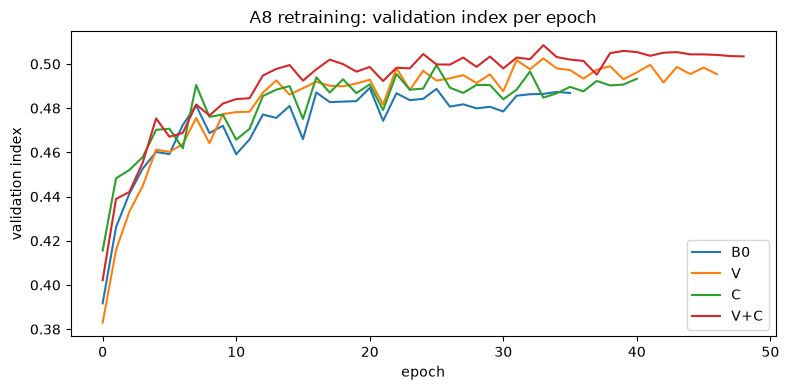

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
for name, m in MODELS.items():
    ax.plot(m["hist"].epoch, m["hist"].val_index, label=name)
ax.set(xlabel="epoch", ylabel="validation index", title="A8 retraining: validation index per epoch")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "27_training.png", dpi=120)
print(f"Run time {(time.time() - T_START) / 60:.1f} min")